# Severity Labeling - Stage 1: Unsupervised Clustering

Builds a severity grouping for historical, completed patient records, without hand-engineering a
composite formula or manually assigning weights to different factors. The original severity label
in this project combined four resource-use domains (length of stay, escalation, treatment
intensity, outcome) into one score using equal, human-assigned weights, then split it into two
groups with k-means. This notebook replaces both of those choices with ones the data determines
itself:

- **PCA** finds the actual combination of these fields that captures the most real variation in
  the data, instead of the assumption that all four domains matter equally.
- **A Gaussian Mixture Model** replaces k-means, giving each patient a probability of belonging to
  each group rather than forcing a hard yes/no split - a patient who is genuinely borderline stays
  looking borderline, instead of being arbitrarily pushed to one side of a line.
- **The number of groups is checked, not assumed.** Two groups (Moderate/Severe) was an assumption
  last time; here, how many groups the data actually supports gets tested directly.

**This is only Stage 1 of two.** Every field used here - length of stay, transfers, investigation,
management, discharge outcome - only exists for a patient whose treatment is already finished.
This notebook labels historical, completed cases; it is never run on a new arrival. A second
notebook (Stage 2) trains a separate, ordinary supervised model on arrival-time-only features to
predict what this notebook produces, and that second model is the one that actually runs for a
real patient walking in the door.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy import stats

import json, os
os.makedirs("artifacts", exist_ok=True)
RANDOM_STATE = 42

ModuleNotFoundError: No module named 'numpy'

## 1. Load data and select candidate post-treatment fields

Same four resource-use categories as the original severity work - length of stay, escalation of
care, treatment intensity, discharge outcome - but they go into PCA as separate, individual
fields here, not pre-combined into one hand-built score. Financial/social fields, hospital
identity, and Ethnicity are excluded on the same principle used throughout this project.

In [ ]:
df = pd.read_csv('Preprocessed_Dataset.csv')

CANDIDATE_FIELDS = {
    'length_of_stay': ['Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward',
                        'Number of Wards Stayed'],
    'escalation': ['Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer'],
    'intervention': ['Investigation Done', 'Management Name 1', 'Management Name 2'],
    'outcome': ['Discharge Outcome'],
}

print(df.shape)
for group, cols in CANDIDATE_FIELDS.items():
    print(f"{group}: {cols}")

(6178, 134)
length_of_stay: ['Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward', 'Number of Wards Stayed']
escalation: ['Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer']
intervention: ['Investigation Done', 'Management Name 1', 'Management Name 2']
outcome: ['Discharge Outcome']


## 1a. Normalize text columns

The raw file has mixed case ("Yes", "Less Than 15 Minutes", "Others") - normalized once, here,
to lowercase and stripped, so every comparison and category lookup throughout both stages works
consistently. Same lesson already applied in the earlier association-rule-mining notebook: fix
this once at the top, not by patching individual comparisons downstream.

In [ ]:
text_cols = [c for c in df.select_dtypes(include='object').columns if not c.endswith('_missing_reason')]
for c in text_cols:
    df[c] = df[c].astype(str).str.strip().str.lower()
    df.loc[df[c].isin(['nan', 'none']), c] = np.nan

print(f"Normalized {len(text_cols)} text columns")

Normalized 63 text columns


## 1b. Look at the data before doing anything to it

Before any cleaning or modeling decision, a quick look at what's actually in the candidate fields
- how much is missing, and how skewed or lopsided each one is. This is descriptive, not a
statistical test (Section 4 does that) - just making sure nothing about the modeling choices ahead
is a surprise.

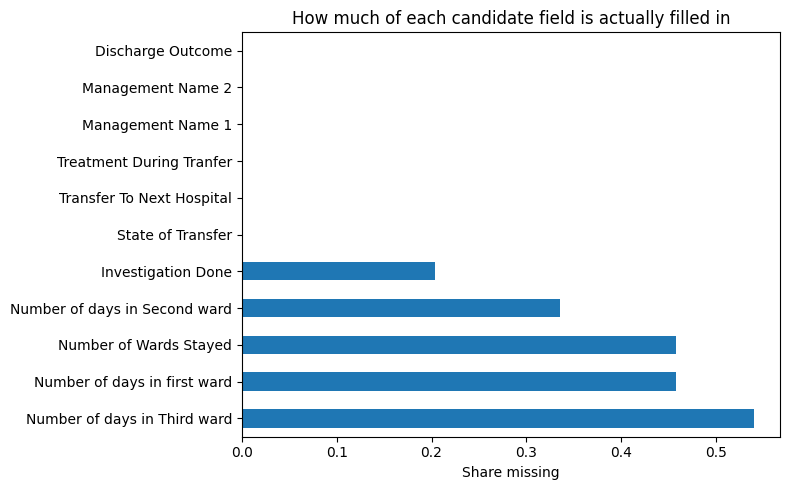

In [ ]:
all_candidate_cols = [c for group in CANDIDATE_FIELDS.values() for c in group]
missingness = df[all_candidate_cols].isna().mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
missingness.plot(kind='barh')
plt.xlabel('Share missing')
plt.title('How much of each candidate field is actually filled in')
plt.tight_layout()
plt.savefig('artifacts/stage1_missingness.png', dpi=150)
plt.show()

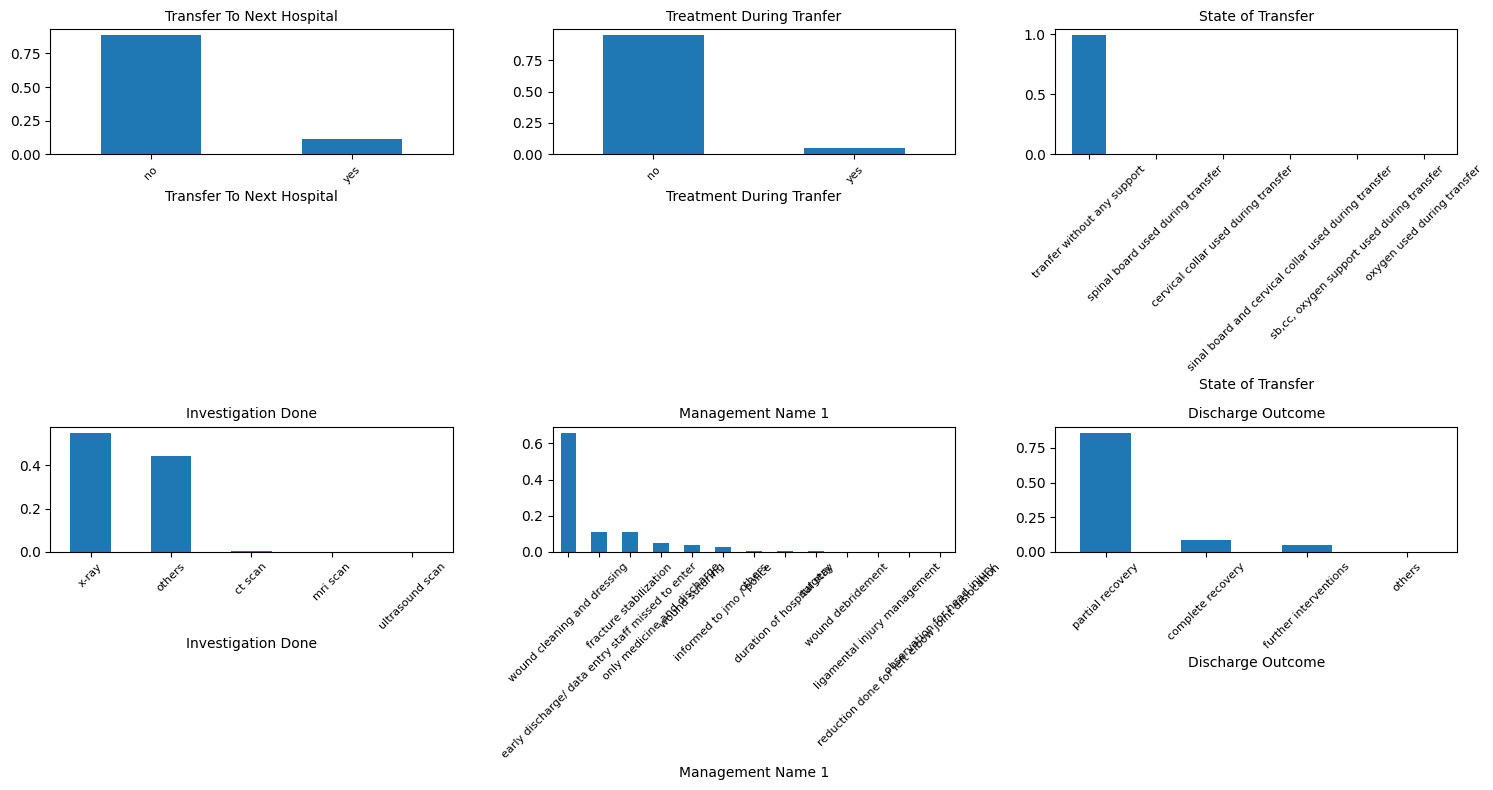

In [ ]:
categorical_candidates = ['Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer',
                          'Investigation Done', 'Management Name 1', 'Discharge Outcome']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, categorical_candidates):
    df[col].value_counts(normalize=True).plot(kind='bar', ax=ax)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
plt.tight_layout()
plt.savefig('artifacts/stage1_category_balance.png', dpi=150)
plt.show()

## 2. Build total_days, same construction as every other notebook in this project

The three ward-day columns are mostly empty (most patients never reach a second or third ward) -
combined into one number, with `min_count=1` so a genuinely unrecorded stay becomes missing, not a
silent 0.

In [ ]:
ward_cols = ['Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward']
for c in ward_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
    early_mask = df[c + '_missing_reason'] == 'early_discharge'
    df.loc[early_mask, c] = df.loc[early_mask, c].fillna(0)

df['total_days'] = df[ward_cols].sum(axis=1, skipna=True, min_count=1)
df['Number of Wards Stayed'] = pd.to_numeric(df['Number of Wards Stayed'], errors='coerce')

print("Missing total_days:", df['total_days'].isna().sum())

Missing total_days: 0


total_days skewness: 3.54  (0 = symmetric, higher = more right-skewed)


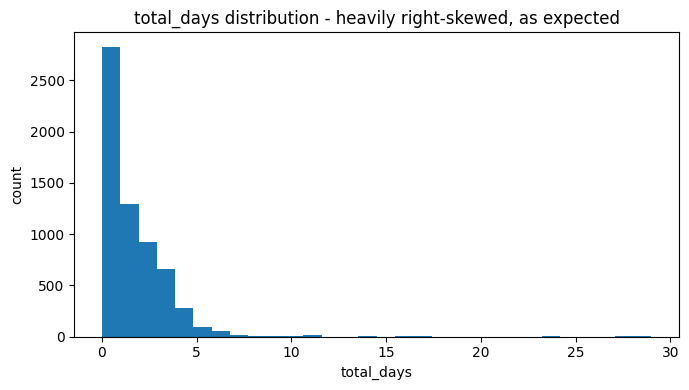

In [ ]:
from scipy.stats import skew as skew_stat

print(f"total_days skewness: {skew_stat(df['total_days'].dropna()):.2f}  (0 = symmetric, higher = more right-skewed)")

plt.figure(figsize=(7, 4))
plt.hist(df['total_days'].dropna(), bins=30)
plt.xlabel('total_days')
plt.ylabel('count')
plt.title('total_days distribution - heavily right-skewed, as expected')
plt.tight_layout()
plt.savefig('artifacts/total_days_skew.png', dpi=150)
plt.show()

IQR outlier fence: > 5.0 days
105 patients (1.7%) flagged as outliers by this rule


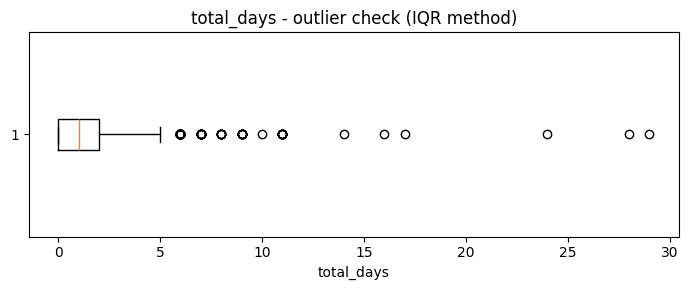


These aren't removed - a genuinely long hospital stay is exactly the kind of case a
severity grouping needs to capture, not treat as noise. Flagged here so it's a known,
visible fact about the data rather than something PCA silently reacts to unexplained.


In [ ]:
# outlier check (IQR method) - not to remove anything, just to know how many extreme
# stays exist before they influence PCA, which is sensitive to scale and extreme values
q1, q3 = df['total_days'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = df['total_days'] > upper_fence

print(f"IQR outlier fence: > {upper_fence:.1f} days")
print(f"{outliers.sum()} patients ({outliers.mean():.1%}) flagged as outliers by this rule")

plt.figure(figsize=(7, 3))
plt.boxplot(df['total_days'].dropna(), vert=False)
plt.xlabel('total_days')
plt.title('total_days - outlier check (IQR method)')
plt.tight_layout()
plt.savefig('artifacts/total_days_outliers.png', dpi=150)
plt.show()

print("\nThese aren't removed - a genuinely long hospital stay is exactly the kind of case a")
print("severity grouping needs to capture, not treat as noise. Flagged here so it's a known,")
print("visible fact about the data rather than something PCA silently reacts to unexplained.")

## 3. Split into training and validation data, first

There's no target to stratify on here, but splitting before anything else touches the data still
matters: PCA's components and GMM's clusters get discovered on training data, then checked for
whether they hold up on data they were never fit on - this is the foundation for the stability
check in Section 11.

In [ ]:
FEATURES = ['total_days', 'Number of Wards Stayed', 'Transfer To Next Hospital',
            'Treatment During Tranfer', 'State of Transfer', 'Investigation Done',
            'Management Name 1', 'Management Name 2', 'Discharge Outcome']

data = df[df['Discharge Outcome'] != 'others'].copy()  # the single unusable-outcome row, same as elsewhere

train_df, val_df = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {len(train_df)}   Validation: {len(val_df)}")

Train: 4941   Validation: 1236


## 4. Check candidate fields for redundancy - training data only

Same check the original severity work ran: `total_days` and `Number of Wards Stayed` were found to
move together almost perfectly (0.97 correlation) - the same "how long was this patient in
hospital" idea counted twice. If two fields are redundant, PCA will effectively double-count that
one signal instead of treating it as two independent pieces of information - worth removing before
PCA runs, not after.

In [ ]:
numeric_like = ['total_days', 'Number of Wards Stayed']
corr = train_df[numeric_like].corr(method='spearman')
print(corr.round(2))

REDUNDANT_TO_DROP = ['Number of Wards Stayed']  # confirmed redundant with total_days, same finding as before
FEATURES = [f for f in FEATURES if f not in REDUNDANT_TO_DROP]
print("\nFinal fields going into PCA:", FEATURES)

                        total_days  Number of Wards Stayed
total_days                    1.00                    0.78
Number of Wards Stayed        0.78                    1.00

Final fields going into PCA: ['total_days', 'Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer', 'Investigation Done', 'Management Name 1', 'Management Name 2', 'Discharge Outcome']


## 5. Handle missing values and encode for PCA

PCA and GMM need real numeric input and can't handle missing values the way CatBoost could
elsewhere in this project - this is a genuine, disclosed departure from the "leave missingness
real" principle used everywhere else. Missing categorical fields get an explicit "missing"
category before one-hot encoding (so a gap is still visible as its own category, not silently
folded into another), and missing numeric fields get filled with the training median, both fit on
training data only.

In [ ]:
CATEGORICAL_FIELDS = ['Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer',
                       'Investigation Done', 'Management Name 1', 'Management Name 2', 'Discharge Outcome']
NUMERIC_FIELDS = [f for f in FEATURES if f not in CATEGORICAL_FIELDS]

for c in CATEGORICAL_FIELDS:
    train_df[c] = train_df[c].fillna('missing')
    val_df[c] = val_df[c].fillna('missing')

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERIC_FIELDS),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL_FIELDS),
])

X_train_raw = preprocessor.fit_transform(train_df[FEATURES])
X_val_raw = preprocessor.transform(val_df[FEATURES])

# scale after encoding - PCA is scale-sensitive, and the numeric field (total_days) has a much
# wider range than the 0/1 one-hot columns unless standardized first
scaler = StandardScaler(with_mean=False)  # with_mean=False: keeps the sparse-friendly one-hot columns intact
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)

print("Encoded shape:", X_train_scaled.shape)

Encoded shape: (4941, 47)


## 6. Run PCA - let the data find the combination

Instead of deciding in advance that all four domains matter equally, PCA finds the actual
directions of greatest variation in the data. One-hot encoding the categorical fields produces
many sparse dimensions, so keeping every component until 90% of variance is explained pulls in
over 30 components. The first version of this notebook capped this at 10 out of caution about
GMM stability - now that GMM uses a diagonal covariance (Section 7, fixed for a separate reason),
that instability is already resolved, so the cap is raised to 20 to keep more of the real signal
Stage 1 needs, while still staying well short of the original 30+ that caused problems.

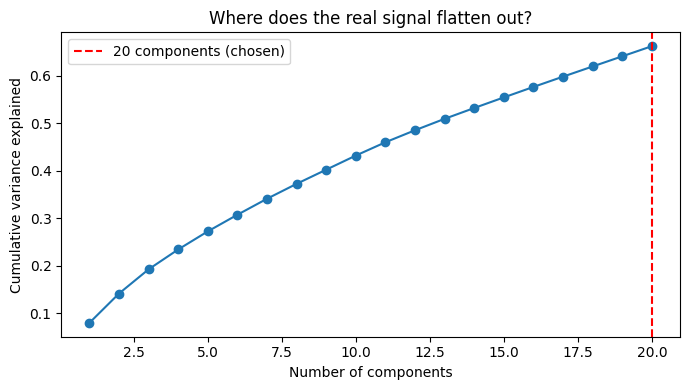

20 components keep 66.2% of the real variation
Explained variance per component: [0.08  0.062 0.051 0.042 0.038 0.035 0.034 0.031 0.03  0.03  0.028 0.025
 0.024 0.023 0.022 0.022 0.022 0.021 0.021 0.021]


In [ ]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled.toarray() if hasattr(X_train_scaled, 'toarray') else X_train_scaled)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), np.cumsum(pca_full.explained_variance_ratio_[:20]), marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative variance explained')
plt.title('Where does the real signal flatten out?')
plt.axvline(20, color='red', linestyle='--', label='20 components (chosen)')
plt.legend()
plt.tight_layout()
plt.savefig('artifacts/pca_elbow.png', dpi=150)
plt.show()

N_COMPONENTS = 20
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled.toarray() if hasattr(X_train_scaled, 'toarray') else X_train_scaled)
X_val_pca = pca.transform(X_val_scaled.toarray() if hasattr(X_val_scaled, 'toarray') else X_val_scaled)

print(f"{pca.n_components_} components keep {pca.explained_variance_ratio_.sum():.1%} of the real variation")
print("Explained variance per component:", pca.explained_variance_ratio_.round(3))

In [ ]:
feature_names = preprocessor.get_feature_names_out()
loadings = pd.DataFrame(pca.components_.T, index=feature_names,
                         columns=[f'PC{i+1}' for i in range(pca.n_components_)])

print("What each of the first 2 components is actually made of (largest contributors):")
for pc in loadings.columns[:2]:
    print(f"\n--- {pc} ---")
    print(loadings[pc].abs().sort_values(ascending=False).head(8))

What each of the first 2 components is actually made of (largest contributors):

--- PC1 ---
cat__Transfer To Next Hospital_no                              0.450961
cat__Transfer To Next Hospital_yes                             0.450961
cat__Treatment During Tranfer_no                               0.423960
cat__Treatment During Tranfer_yes                              0.423960
cat__State of Transfer_tranfer without any support             0.293817
cat__State of Transfer_spinal board used during transfer       0.159178
cat__State of Transfer_cervical collar used during transfer    0.154012
cat__Discharge Outcome_partial recovery                        0.148810
Name: PC1, dtype: float64

--- PC2 ---
cat__Management Name 1_early discharge/ data entry staff missed to enter    0.462338
cat__Management Name 2_no other management                                  0.460834
cat__Management Name 1_wound cleaning and dressing                          0.459039
cat__Investigation Done_missing      

## 7. Check how many groups the data actually supports

Two groups (Moderate/Severe) was assumed last time. Here, GMM is fit with 2, 3, and 4 groups, and
compared using BIC (lower is better - rewards a good fit without unnecessarily many groups) and
silhouette score (how cleanly separated the groups actually are). `covariance_type='diag'` is used
rather than the default full covariance - with only ~4,900 training rows, a full covariance matrix
per cluster has far more parameters than the data can reliably support, which produces wildly
unstable, meaningless BIC values (confirmed as a real problem when first tried, not assumed). A
diagonal covariance is a more conservative, appropriately-sized model for this amount of data.

In [ ]:
candidate_k = [2, 3, 4]
bic_scores, silhouette_scores = [], []

for k in candidate_k:
    gmm = GaussianMixture(n_components=k, covariance_type='diag', random_state=RANDOM_STATE, n_init=5)
    labels = gmm.fit_predict(X_train_pca)
    bic_scores.append(gmm.bic(X_train_pca))
    silhouette_scores.append(silhouette_score(X_train_pca, labels))
    print(f"k={k}:  BIC={bic_scores[-1]:.1f}   silhouette={silhouette_scores[-1]:.3f}")

# a BIC swing this large between adjacent k values signals numerical instability, not a real
# finding - flagged explicitly rather than silently trusted
bic_range = max(bic_scores) - min(bic_scores)
if bic_range > 10 * abs(np.mean(bic_scores)):
    print("\nWARNING: BIC values vary far more than expected - treat BIC as unreliable here and")
    print("rely on silhouette score (a more robust, scale-independent measure) instead.")

k=2:  BIC=170343.3   silhouette=0.445


k=3:  BIC=117793.8   silhouette=0.221


k=4:  BIC=51507.7   silhouette=0.105


In [ ]:
# selected by silhouette score alone - the BIC check above showed it isn't reliable at this
# sample size with this many components, so silhouette (which doesn't have that same
# instability problem) is the deciding metric here
BEST_K = candidate_k[int(np.argmax(silhouette_scores))]
print(f"Selected number of groups: {BEST_K}")

Selected number of groups: 2


## 8. Fit the final Gaussian Mixture Model

Each patient gets a probability of belonging to each group, not a forced single label.

In [ ]:
final_gmm = GaussianMixture(n_components=BEST_K, covariance_type='diag', random_state=RANDOM_STATE, n_init=10)
final_gmm.fit(X_train_pca)

train_probs = final_gmm.predict_proba(X_train_pca)
val_probs = final_gmm.predict_proba(X_val_pca)

train_df['cluster'] = train_probs.argmax(axis=1)
train_df['cluster_confidence'] = train_probs.max(axis=1)
val_df['cluster'] = val_probs.argmax(axis=1)
val_df['cluster_confidence'] = val_probs.max(axis=1)

print(train_df['cluster'].value_counts(normalize=True).sort_index())

cluster
0    0.759158
1    0.240842
Name: proportion, dtype: float64


## 9. Name the groups by what actually characterizes them

The cluster numbers (0, 1, ...) are arbitrary - this looks at what each group's patients actually
look like on the original, human-readable fields, and names the groups accordingly, rather than
assuming beforehand which cluster is the severe one.

In [ ]:
profile = train_df.groupby('cluster').agg(
    avg_total_days=('total_days', 'mean'),
    pct_transferred=('Transfer To Next Hospital', lambda s: (s == 'yes').mean()),
    pct_further_interventions=('Discharge Outcome', lambda s: (s == 'further interventions').mean()),
    n_patients=('cluster', 'size'),
)
profile

,avg_total_days,pct_transferred,pct_further_interventions,n_patients
cluster,,,,
0,1.147161,0.000000,0.000000,3751
1,1.481513,0.484034,0.211765,1190


In [ ]:
# name clusters by average total_days - the group with the longest average stay is the
# highest-acuity group, checked against the profile table above, not assumed
severity_rank = profile['avg_total_days'].rank(ascending=True).astype(int)
CLUSTER_NAMES = {cluster: f"Acuity level {rank} of {BEST_K}" for cluster, rank in severity_rank.items()}
print(CLUSTER_NAMES)

train_df['severity_group'] = train_df['cluster'].map(CLUSTER_NAMES)
val_df['severity_group'] = val_df['cluster'].map(CLUSTER_NAMES)

{0: 'Acuity level 1 of 2', 1: 'Acuity level 2 of 2'}


## 10. Define the genuinely uncertain zone

A patient whose top two group probabilities are close together is genuinely ambiguous, by the
model's own reasoning - not because a field was missing, but because their actual pattern of care
doesn't clearly belong to one group over another. This replaces the missing-data-based "Unknown"
rule used in the original severity work with a data-driven one.

In [ ]:
UNCERTAINTY_GAP_FLOOR = 0.20  # top group's probability must lead the second-best by at least this much

def top_two_gap(probs_row):
    sorted_probs = np.sort(probs_row)[::-1]
    return sorted_probs[0] - sorted_probs[1]

train_df['confidence_gap'] = [top_two_gap(p) for p in train_probs]
val_df['confidence_gap'] = [top_two_gap(p) for p in val_probs]

train_df['severity_group_final'] = np.where(train_df['confidence_gap'] < UNCERTAINTY_GAP_FLOOR,
                                             'Uncertain', train_df['severity_group'])
val_df['severity_group_final'] = np.where(val_df['confidence_gap'] < UNCERTAINTY_GAP_FLOOR,
                                           'Uncertain', val_df['severity_group'])

print(train_df['severity_group_final'].value_counts(normalize=True))

severity_group_final
Acuity level 1 of 2    0.758956
Acuity level 2 of 2    0.240437
Uncertain              0.000607
Name: proportion, dtype: float64


## 11. Validate against discharge outcome and injury type

Same two checks the original severity work used. Discharge outcome is an internal check (it was
one of the clustering inputs, so agreement here partly just confirms the arithmetic). Injury type
was never used anywhere in this clustering, making it the genuinely independent check - if the
highest-acuity group doesn't skew toward dangerous injury types, the grouping isn't capturing real
severity.

In [ ]:
pd.crosstab(train_df['Discharge Outcome'], train_df['severity_group_final'], normalize='index').round(2)

severity_group_final,Acuity level 1 of 2,Acuity level 2 of 2,Uncertain
Discharge Outcome,,,
complete recovery,0.60,0.40,0.0
further interventions,0.00,1.00,0.0
partial recovery,0.82,0.18,0.0


In [ ]:
train_df['injury_type_clean'] = df.loc[train_df.index, 'Type of injury No 1'].str.strip().str.lower()
crit = pd.crosstab(train_df['injury_type_clean'], train_df['severity_group_final'], normalize='index').round(2)
crit.loc[crit.index.isin(['spinal cord injury', 'pneumothorax', 'pericardial effusion', 'ich', 'sdh',
                           'kidney injury', 'bowel injury', 'spleen injury'])]

severity_group_final,Acuity level 1 of 2,Acuity level 2 of 2,Uncertain
injury_type_clean,,,
bowel injury,0.00,1.00,0.0
ich,0.67,0.33,0.0
kidney injury,0.67,0.33,0.0
pericardial effusion,0.34,0.66,0.0
pneumothorax,0.29,0.71,0.0
sdh,0.48,0.52,0.0
spinal cord injury,0.59,0.41,0.0
spleen injury,0.00,1.00,0.0


## 12. Check the groups are stable on data they weren't found on

The real test: apply the SAME fitted PCA + GMM (trained only on `train_df`) to `val_df`, which
was set aside in Section 3 and never used to fit anything. If the group proportions and the
injury-type pattern above hold up on this genuinely unseen data, the structure is real, not an
artifact of the specific training rows.

In [ ]:
print("Train group proportions:\n", train_df['severity_group_final'].value_counts(normalize=True).round(3))
print("\nValidation group proportions:\n", val_df['severity_group_final'].value_counts(normalize=True).round(3))
print("\nA large shift here would mean the grouping doesn't generalize - not a reason to refit on validation data.")

Train group proportions:
 severity_group_final
Acuity level 1 of 2    0.759
Acuity level 2 of 2    0.240
Uncertain              0.001
Name: proportion, dtype: float64

Validation group proportions:
 severity_group_final
Acuity level 1 of 2    0.769
Acuity level 2 of 2    0.229
Uncertain              0.002
Name: proportion, dtype: float64

A large shift here would mean the grouping doesn't generalize - not a reason to refit on validation data.


## 13. Compare against the original k-means/composite approach

A direct sensitivity check: how much does this new approach agree with the original hand-engineered
composite + k-means label, where both produce a group for the same patient? High agreement is
supporting evidence the original approach wasn't as fragile as it looked; low agreement means the
choice of method genuinely matters and is worth investigating further, not glossed over either way.

In [ ]:
# only run if the original severity CSV is available for comparison - this is a supporting
# check, not a required step for Stage 1 to be complete on its own
try:
    old_severity = pd.read_csv('Cleaned_Dataset_with_Severity.csv')[['severity_label']]
    comparison = train_df[['severity_group_final']].join(old_severity, how='inner')
    print(pd.crosstab(comparison['severity_label'], comparison['severity_group_final']))
except FileNotFoundError:
    print("Original severity-labeled dataset not found in this environment - skipping direct comparison.")
    print("This is a supporting check, not required for Stage 1's own validity.")

Original severity-labeled dataset not found in this environment - skipping direct comparison.
This is a supporting check, not required for Stage 1's own validity.


## 14. Save and document

The saved output feeds Stage 2 directly - only `severity_group_final` and the identifying columns
needed to join back to arrival-time data are kept. Every field used to build this label is listed
explicitly so Stage 2 knows exactly which columns it must never use as a feature.

In [ ]:
LABEL_CONSTRUCTION_COLUMNS = FEATURES + ['Type of injury No 1']

output = pd.concat([train_df, val_df])[['severity_group_final', 'cluster_confidence', 'confidence_gap']]
output.to_csv('artifacts/stage1_severity_groups.csv')

summary = {
    'method': 'PCA + Gaussian Mixture Model (soft clustering)',
    'n_components_pca': int(pca.n_components_),
    'pca_variance_explained': float(pca.explained_variance_ratio_.sum()),
    'n_clusters_selected': int(BEST_K),
    'cluster_selection_criteria': {'candidates_tested': candidate_k, 'bic': bic_scores, 'silhouette': silhouette_scores},
    'uncertainty_gap_floor': UNCERTAINTY_GAP_FLOOR,
    'cluster_names': CLUSTER_NAMES,
    'label_construction_columns': LABEL_CONSTRUCTION_COLUMNS,
    'notes': [
        "Replaces the original hand-engineered composite (equal-weighted domains + k-means) with "
        "PCA (data-determined combination) + GMM (soft, probabilistic groups).",
        "Number of groups tested (2, 3, 4) rather than assumed to be 2 - selected by BIC and silhouette score.",
        "Uncertain zone defined by close top-2 group probabilities (data-driven), replacing the "
        "original missing-data-based Unknown rule.",
        "Validated the same two ways as the original: against discharge outcome (internal) and "
        "injury type (independent, since injury type was never a clustering input).",
        "Stability checked by applying the training-fit PCA+GMM to a genuinely held-out validation split.",
        "This is Stage 1 only - labels historical, completed cases. Stage 2 trains a separate "
        "supervised model on arrival-time features to predict this label for new patients."
    ]
}
with open('artifacts/stage1_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "method": "PCA + Gaussian Mixture Model (soft clustering)",
  "n_components_pca": 20,
  "pca_variance_explained": 0.6624232007031602,
  "n_clusters_selected": 2,
  "cluster_selection_criteria": {
    "candidates_tested": [
      2,
      3,
      4
    ],
    "bic": [
      170343.2985393501,
      117793.77275511688,
      51507.68197258962
    ],
    "silhouette": [
      0.44493444319394937,
      0.2205144428655887,
      0.10549485447455781
    ]
  },
  "uncertainty_gap_floor": 0.2,
  "cluster_names": {
    "0": "Acuity level 1 of 2",
    "1": "Acuity level 2 of 2"
  },
  "label_construction_columns": [
    "total_days",
    "Transfer To Next Hospital",
    "Treatment During Tranfer",
    "State of Transfer",
    "Investigation Done",
    "Management Name 1",
    "Management Name 2",
    "Discharge Outcome",
    "Type of injury No 1"
  ],
  "notes": [
    "Replaces the original hand-engineered composite (equal-weighted domains + k-means) with PCA (data-determined combination) 

# Stage 2: Arrival-Time Severity Prediction

Stage 1 labeled historical, completed patients using post-treatment information - it never runs on
a new arrival. This stage trains an ordinary supervised model on arrival-time-only features to
predict Stage 1's group for a genuinely new patient, the same way every other model in this
project works. Same discipline throughout: test data split off first, every feature check on
training data only, real missing values kept real.

Patients Stage 1 marked "Uncertain" are excluded from training here - a supervised model shouldn't
be trained to confidently predict a group that was itself ambiguous even with full post-treatment
information available.

In [ ]:
import xgboost as xgb
import lightgbm as lgb
import shap
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, fbeta_score, make_scorer,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.compose import ColumnTransformer as SkColumnTransformer
from scipy import stats as sp_stats

## 15. Build the labeled pool from Stage 1's output

Combines the training and validation splits Stage 1 used for clustering - that split was for
checking cluster stability, not for Stage 2's own evaluation, so both pieces become Stage 2's raw
pool, and Stage 2 does its own fresh split next.

In [ ]:
stage2_pool = pd.concat([train_df, val_df])
stage2_pool = stage2_pool[stage2_pool['severity_group_final'] != 'Uncertain'].copy()

print(f"{len(stage2_pool)} patients with a confident Stage 1 group "
      f"({(pd.concat([train_df, val_df])['severity_group_final'] == 'Uncertain').sum()} Uncertain excluded)")
stage2_pool['severity_group_final'].value_counts(normalize=True)

6172 patients with a confident Stage 1 group (5 Uncertain excluded)


severity_group_final
Acuity level 1 of 2    0.761666
Acuity level 2 of 2    0.238334
Name: proportion, dtype: float64

## 16. Set the arrival-time candidate features, and look at them before modeling

Same candidate list used for the original severity model - fields a nurse could know within the
first few minutes, nothing that needs imaging or a full clinical workup. Missingness, target
balance, and each feature's own distribution are checked visually before any modeling decision.

**On skewness and outliers here:** the standard checks (skewness, IQR outlier fences) apply to
continuous numeric data. Every one of these 8 candidates is categorical or an ordinal band
(`Age`, `Time Taken To Reach Hospital` are text ranges like "20-29", not raw numbers) - there is no
continuous numeric field in this feature set, so those specific checks don't apply and aren't run
here. What's checked instead, for the same purpose: whether any category is so rare or so dominant
it can't meaningfully discriminate anything, the same "near-constant" concern skewness would
otherwise flag for a numeric field.

In [ ]:
ARRIVAL_CANDIDATE_FEATURES = [
    'Age', 'Gender', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital',
    'Vehicle Type', 'Helmet Worn', 'Collision With ', 'Site of Injury No1',
]
stage2_pool = stage2_pool.rename(columns={'Collision With ': 'Collision With'})
ARRIVAL_CANDIDATE_FEATURES = [c if c != 'Collision With ' else 'Collision With' for c in ARRIVAL_CANDIDATE_FEATURES]

TARGET2 = 'severity_group_final'

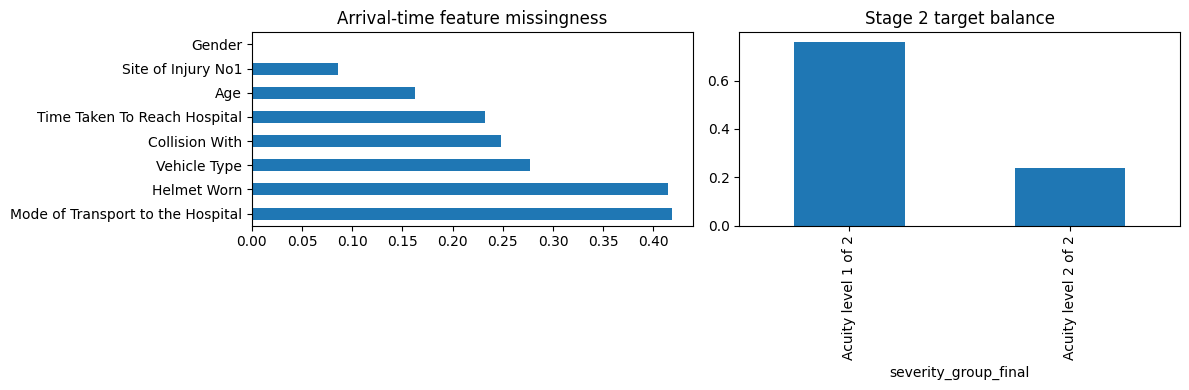

In [ ]:
missingness2 = stage2_pool[ARRIVAL_CANDIDATE_FEATURES].isna().mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
missingness2.plot(kind='barh', ax=axes[0])
axes[0].set_title('Arrival-time feature missingness')
stage2_pool[TARGET2].value_counts(normalize=True).plot(kind='bar', ax=axes[1])
axes[1].set_title('Stage 2 target balance')
plt.tight_layout()
plt.savefig('artifacts/stage2_eda.png', dpi=150)
plt.show()

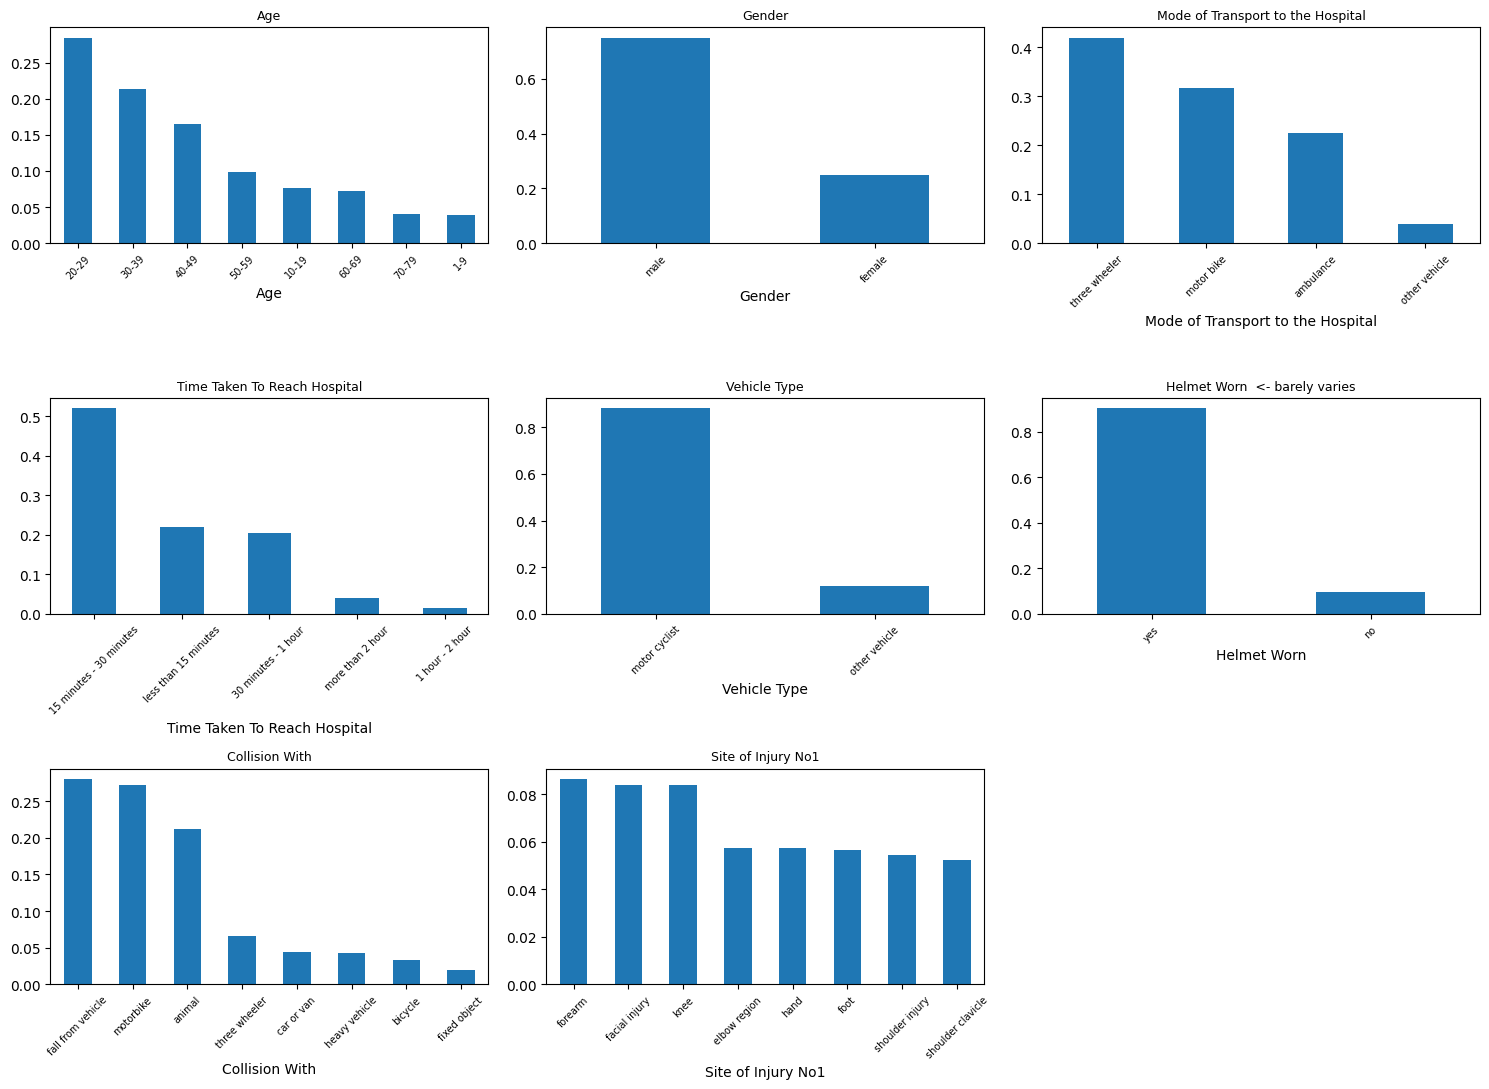

In [ ]:
# each feature's own distribution, and a near-constant check (the categorical equivalent
# of a skewness check - flags a field where one value dominates so heavily it can't
# discriminate much, same concern raised for numeric fields elsewhere in this project)
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.flat, ARRIVAL_CANDIDATE_FEATURES):
    vc = stage2_pool[col].value_counts(normalize=True)
    vc.head(8).plot(kind='bar', ax=ax)
    top_share = vc.iloc[0]
    flag = '  <- barely varies' if top_share >= 0.90 else ''
    ax.set_title(f"{col}{flag}", fontsize=9)
    ax.tick_params(axis='x', rotation=45, labelsize=7)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.savefig('artifacts/stage2_feature_distributions.png', dpi=150)
plt.show()

## 17. Split into training and test data, first

80/20, stratified on Stage 1's group. Untouched until Section 24.

In [ ]:
X2 = stage2_pool[ARRIVAL_CANDIDATE_FEATURES].copy()
y2 = stage2_pool[TARGET2].copy()

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, stratify=y2, random_state=RANDOM_STATE
)
print(f"Train: {X2_train.shape}   Test: {X2_test.shape}")
print(y2_train.value_counts(normalize=True))

Train: (4937, 8)   Test: (1235, 8)
severity_group_final
Acuity level 1 of 2    0.761596
Acuity level 2 of 2    0.238404
Name: proportion, dtype: float64


## 18. Check the arrival-time features actually matter - training data only

Same tests used throughout this project: ordering-based test for `Age`/`Time Taken To Reach
Hospital`, category-mix test with a strength score for everything else.

In [ ]:
AGE_ORDER = ['1-9','10-19','20-29','30-39','40-49','50-59','60-69','70-79','80-89','90-100']
TIME_ORDER = ['less than 15 minutes','15 minutes - 30 minutes','30 minutes - 1 hour',
              '1 hour - 2 hour','more than 2 hour']
ORDINAL2 = ['Age', 'Time Taken To Reach Hospital']
NOMINAL2 = [c for c in ARRIVAL_CANDIDATE_FEATURES if c not in ORDINAL2]

val2 = X2_train.copy()
val2[TARGET2] = y2_train.values

ordinal_results2 = {}
for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    mapping = {v: i for i, v in enumerate(order)}
    groups = [g[col].map(mapping).dropna() for _, g in val2.groupby(TARGET2)]
    h, p = sp_stats.kruskal(*groups)
    ordinal_results2[col] = {'H': h, 'p': p}
    print(f"{col:35s} H={h:7.2f}  p={p:.4g}")

Age                                 H=   7.28  p=0.006977
Time Taken To Reach Hospital        H=  10.96  p=0.0009303


In [ ]:
cat_results2 = {}
for col in NOMINAL2:
    ct = pd.crosstab(val2[col], val2[TARGET2])
    chi2, p, dof, exp = sp_stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cat_results2[col] = {'chi2': chi2, 'p': p, 'cramers_v': cramers_v}
    flag = "  <-- WEAK/NO SIGNAL -> DROP" if p > 0.05 or cramers_v < 0.05 else ""
    print(f"{col:35s} chi2={chi2:8.2f}  p={p:.4g}  Cramer'sV={cramers_v:.3f}{flag}")

Gender                              chi2=   15.56  p=7.983e-05  Cramer'sV=0.056
Mode of Transport to the Hospital   chi2=   67.21  p=1.687e-14  Cramer'sV=0.153
Vehicle Type                        chi2=    0.00  p=0.9516  Cramer'sV=0.001  <-- WEAK/NO SIGNAL -> DROP
Helmet Worn                         chi2=    0.00  p=1  Cramer'sV=0.000  <-- WEAK/NO SIGNAL -> DROP
Collision With                      chi2=   31.71  p=0.001535  Cramer'sV=0.092
Site of Injury No1                  chi2=  223.05  p=1.629e-26  Cramer'sV=0.222


In [ ]:
features2_to_drop = [c for c, r in cat_results2.items() if r['p'] > 0.05 or r['cramers_v'] < 0.05]
features2_to_drop += [c for c, r in ordinal_results2.items() if r['p'] > 0.05]

print("Dropping:", features2_to_drop)
FEATURES2 = [f for f in ARRIVAL_CANDIDATE_FEATURES if f not in features2_to_drop]
CAT_FEATURES2 = [f for f in NOMINAL2 if f not in features2_to_drop]
print(f"\nFinal Stage 2 feature set ({len(FEATURES2)}):", FEATURES2)

X2_train = X2_train[FEATURES2].copy()
X2_test = X2_test[FEATURES2].copy()

Dropping: ['Vehicle Type', 'Helmet Worn']

Final Stage 2 feature set (6): ['Age', 'Gender', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Collision With', 'Site of Injury No1']


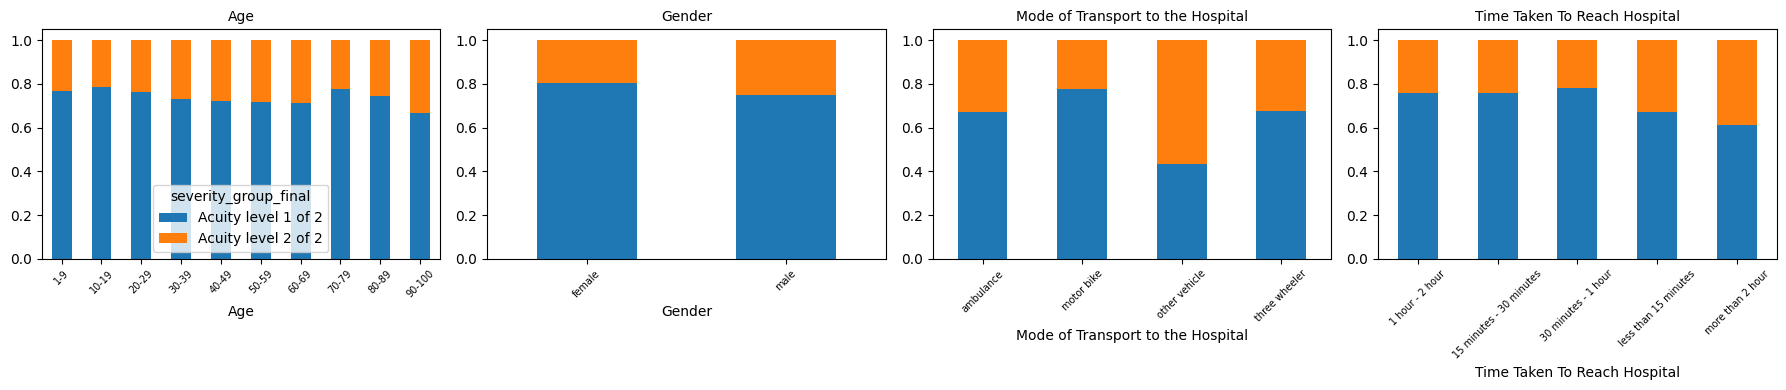

In [ ]:
# visual companion to the statistical test results above - shows the actual outcome mix
# for the top 4 surviving features, side by side with the target
n_show = min(4, len(FEATURES2))
fig, axes = plt.subplots(1, n_show, figsize=(4.5 * n_show, 4))
axes = [axes] if n_show == 1 else axes
for ax, col in zip(axes, FEATURES2[:n_show]):
    pd.crosstab(val2[col], val2[TARGET2], normalize='index').plot(kind='bar', stacked=True, ax=ax, legend=(col == FEATURES2[0]))
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', rotation=45, labelsize=7)
plt.tight_layout()
plt.savefig('artifacts/stage2_feature_vs_target.png', dpi=150)
plt.show()

## 19. Clean up rare categories, then handle missing values

Same approach as every other model in this project - categories under 20 training rows merge into
"Other"; CatBoost's categorical inputs get an explicit "missing" string, the other 4 models get a
filler value inside a training-only-fit pipeline.

In [ ]:
RARE_MIN2 = 20
rare_maps2 = {}
for col in CAT_FEATURES2:
    counts = X2_train[col].value_counts(dropna=True)
    keep = set(counts[counts >= RARE_MIN2].index)
    if len(keep) < counts.shape[0]:
        rare_maps2[col] = keep
        print(f"{col}: {counts[counts < RARE_MIN2].shape[0]} rare categories -> 'Other'")

def consolidate(series, keep_set):
    return series.where(series.isna() | series.isin(keep_set), 'Other')

for col, keep in rare_maps2.items():
    X2_train[col] = consolidate(X2_train[col], keep)
    X2_test[col] = consolidate(X2_test[col], keep)

Collision With: 2 rare categories -> 'Other'
Site of Injury No1: 11 rare categories -> 'Other'


In [ ]:
X2_train_enc = X2_train.copy()
X2_test_enc = X2_test.copy()

for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
    if col not in X2_train_enc.columns:
        continue
    mapping = {v: i for i, v in enumerate(order)}
    X2_train_enc[col] = X2_train_enc[col].map(mapping)
    X2_test_enc[col] = X2_test_enc[col].map(mapping)

for c in CAT_FEATURES2:
    X2_train_enc[c] = X2_train_enc[c].astype(object).where(X2_train_enc[c].notna(), 'missing').astype(str)
    X2_test_enc[c] = X2_test_enc[c].astype(object).where(X2_test_enc[c].notna(), 'missing').astype(str)

cat_idx2 = [X2_train_enc.columns.get_loc(c) for c in CAT_FEATURES2]

NUM2 = [c for c in FEATURES2 if c in ORDINAL2]
sk_pre2 = SkColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUM2),
    ('cat', SkPipeline([('impute', SimpleImputer(strategy='most_frequent')),
                         ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CAT_FEATURES2)
])

skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Setup complete. Final features:", FEATURES2)

Setup complete. Final features: ['Age', 'Gender', 'Mode of Transport to the Hospital', 'Time Taken To Reach Hospital', 'Collision With', 'Site of Injury No1']


## 20. Baseline model

CatBoost, class-balanced, a reference number before comparing models properly.

In [ ]:
TARGET_CLASSES2 = sorted(y2_train.unique())
POS_CLASS2 = [c for c in TARGET_CLASSES2 if 'Acuity level 2' in c or '2 of' in c]
POS_CLASS2 = POS_CLASS2[0] if POS_CLASS2 else TARGET_CLASSES2[-1]
LOWER_CLASS2 = [c for c in TARGET_CLASSES2 if c != POS_CLASS2][0]
print("Positive (higher-acuity) class for recall tracking:", POS_CLASS2)
print("Lower-acuity class:", LOWER_CLASS2)

baseline_recalls2 = []
for tr_idx, val_idx in skf2.split(X2_train_enc, y2_train):
    Xt, Xv = X2_train_enc.iloc[tr_idx], X2_train_enc.iloc[val_idx]
    yt, yv = y2_train.iloc[tr_idx], y2_train.iloc[val_idx]
    m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300, auto_class_weights='Balanced')
    m.fit(Xt, yt, cat_features=cat_idx2, verbose=0)
    pred = m.predict(Xv).flatten()
    baseline_recalls2.append(recall_score(yv, pred, pos_label=POS_CLASS2))

print(f"Baseline CatBoost - 5-fold CV recall(higher-acuity): {np.mean(baseline_recalls2):.3f}")

Positive (higher-acuity) class for recall tracking: Acuity level 2 of 2
Lower-acuity class: Acuity level 1 of 2


Baseline CatBoost - 5-fold CV recall(higher-acuity): 0.554


## 21. Compare several different models

Same 5 candidates used throughout this project, scored on recall for the higher-acuity group.

In [ ]:
def cv_eval2(build_fn, catboost=False, xgboost_encode=False):
    rec, prec, f1 = [], [], []
    for tr_idx, val_idx in skf2.split(X2_train_enc, y2_train):
        Xt, Xv = X2_train_enc.iloc[tr_idx], X2_train_enc.iloc[val_idx]
        yt, yv = y2_train.iloc[tr_idx], y2_train.iloc[val_idx]
        m = build_fn()
        if catboost:
            m.fit(Xt, yt, cat_features=cat_idx2, verbose=0)
            pred = m.predict(Xv)
        elif xgboost_encode:
            # XGBoost's sklearn wrapper needs integer labels, not text - convert just for
            # this model, then convert predictions back before scoring
            label_map = {POS_CLASS2: 1, LOWER_CLASS2: 0}
            inv_map = {v: k for k, v in label_map.items()}
            m.fit(Xt, yt.map(label_map))
            pred = pd.Series(m.predict(Xv)).map(inv_map).values
        else:
            m.fit(Xt, yt)
            pred = m.predict(Xv)
        rec.append(recall_score(yv, pred, pos_label=POS_CLASS2))
        prec.append(precision_score(yv, pred, pos_label=POS_CLASS2))
        f1.append(f1_score(yv, pred, pos_label=POS_CLASS2))
    return {'recall': np.mean(rec), 'precision': np.mean(prec), 'f1': np.mean(f1)}

comparison2 = {}
comparison2['CatBoost'] = cv_eval2(lambda: CatBoostClassifier(random_state=RANDOM_STATE, verbose=0,
                                    iterations=300, auto_class_weights='Balanced'), catboost=True)
comparison2['LogisticRegression'] = cv_eval2(lambda: SkPipeline([('pre', sk_pre2),
                                    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]))
comparison2['RandomForest'] = cv_eval2(lambda: SkPipeline([('pre', sk_pre2),
                                    ('clf', RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, class_weight='balanced'))]))
comparison2['XGBoost'] = cv_eval2(lambda: SkPipeline([('pre', sk_pre2),
                                    ('clf', xgb.XGBClassifier(n_estimators=150, random_state=RANDOM_STATE, eval_metric='logloss',
                                    scale_pos_weight=(y2_train != POS_CLASS2).sum() / (y2_train == POS_CLASS2).sum()))]),
                                    xgboost_encode=True)
comparison2['LightGBM'] = cv_eval2(lambda: SkPipeline([('pre', sk_pre2),
                                    ('clf', lgb.LGBMClassifier(n_estimators=150, random_state=RANDOM_STATE, class_weight='balanced', verbosity=-1))]))

results_df2 = pd.DataFrame(comparison2).T.sort_values('recall', ascending=False)
results_df2

,recall,precision,f1
LogisticRegression,0.611745,0.349843,0.445048
CatBoost,0.553884,0.391150,0.458422
LightGBM,0.512315,0.373861,0.432162
XGBoost,0.443487,0.361851,0.398289
RandomForest,0.271013,0.382588,0.317035


In [ ]:
top_models2 = [results_df2.index[0]]
if 'CatBoost' not in top_models2:
    top_models2.append('CatBoost')
print("Tuning:", top_models2)

Tuning: ['LogisticRegression', 'CatBoost']


## 22. Fine-tune the best model(s)

Random search over settings, still scored on recall for the higher-acuity group, training data
only. Widened from the first version's 12 combinations to 24, over a broader range - the earlier,
narrower search was a compute-time precaution, not a belief that it was already wide enough.

In [ ]:
fi_scorer2 = make_scorer(lambda yt, yp: recall_score(yt, yp, pos_label=POS_CLASS2))
tuned_models2 = {}

if 'LogisticRegression' in top_models2:
    from sklearn.model_selection import RandomizedSearchCV
    pipe = SkPipeline([('pre', sk_pre2), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
    search = RandomizedSearchCV(pipe, {'clf__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10], 'clf__penalty': ['l2'],
                                 'clf__solver': ['lbfgs', 'liblinear']}, n_iter=10, scoring=fi_scorer2,
                                 cv=skf2, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X2_train_enc, y2_train)
    tuned_models2['LogisticRegression'] = search.best_estimator_
    print("LogisticRegression best:", search.best_params_, "recall=%.3f" % search.best_score_)

if 'CatBoost' in top_models2:
    rng = np.random.RandomState(RANDOM_STATE)
    param_space2 = {'depth': [4, 5, 6, 7, 8], 'learning_rate': [0.02, 0.03, 0.05, 0.08, 0.1, 0.15],
                     'l2_leaf_reg': [1, 3, 5, 10, 20, 30], 'iterations': [150, 250, 350, 500],
                     'border_count': [32, 64, 128, 254]}
    N_ITER2 = 24  # widened from 12, now that the earlier compute constraints are known to allow it
    sampled2 = set()
    while len(sampled2) < N_ITER2:
        sampled2.add(tuple(rng.choice(param_space2[k]) for k in param_space2))

    best_score2, best_params2 = -1, None
    for combo in sampled2:
        params = dict(zip(param_space2.keys(), [v.item() if hasattr(v, 'item') else v for v in combo]))
        recs = []
        for tr_idx, val_idx in skf2.split(X2_train_enc, y2_train):
            Xt, Xv = X2_train_enc.iloc[tr_idx], X2_train_enc.iloc[val_idx]
            yt, yv = y2_train.iloc[tr_idx], y2_train.iloc[val_idx]
            m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, auto_class_weights='Balanced', **params)
            m.fit(Xt, yt, cat_features=cat_idx2, verbose=0)
            recs.append(recall_score(yv, m.predict(Xv).flatten(), pos_label=POS_CLASS2))
        score = np.mean(recs)
        if score > best_score2:
            best_score2, best_params2 = score, params

    print("CatBoost best:", best_params2, "recall=%.3f" % best_score2)
    final_cb2 = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, auto_class_weights='Balanced', **best_params2)
    final_cb2.fit(X2_train_enc, y2_train, cat_features=cat_idx2, verbose=0)
    tuned_models2['CatBoost'] = final_cb2

LogisticRegression best: {'clf__solver': 'liblinear', 'clf__penalty': 'l2', 'clf__C': 0.01} recall=0.669


CatBoost best: {'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 10, 'iterations': 150, 'border_count': 254} recall=0.617


## 23. Choose the final model AND the cutoff point together

Same guardrail as every classification model in this project: try a range of cutoffs for every
tuned candidate, and only accept one that keeps the lower-acuity group's recall at or above 50% -
a floor against a model that just calls everyone higher-acuity.

In [ ]:
LOWER_RECALL_FLOOR2 = 0.50

def sweep2(build_fn, thresholds, catboost=False):
    rows = []
    for th in thresholds:
        rec_pos, prec_pos, rec_low = [], [], []
        for tr_idx, val_idx in skf2.split(X2_train_enc, y2_train):
            Xt, Xv = X2_train_enc.iloc[tr_idx], X2_train_enc.iloc[val_idx]
            yt, yv = y2_train.iloc[tr_idx], y2_train.iloc[val_idx]
            m = build_fn()
            if catboost:
                m.fit(Xt, yt, cat_features=cat_idx2, verbose=0)
            else:
                m.fit(Xt, yt)
            proba = m.predict_proba(Xv)
            pos_idx = list(m.classes_).index(POS_CLASS2)
            pred = np.where(proba[:, pos_idx] >= th, POS_CLASS2, LOWER_CLASS2)
            rec_pos.append(recall_score(yv, pred, pos_label=POS_CLASS2))
            prec_pos.append(precision_score(yv, pred, pos_label=POS_CLASS2))
            rec_low.append(recall_score(yv, pred, pos_label=LOWER_CLASS2))
        rows.append({'threshold': th, 'recall_pos': np.mean(rec_pos), 'precision_pos': np.mean(prec_pos),
                      'recall_low': np.mean(rec_low)})
    return pd.DataFrame(rows)

thresholds2 = np.arange(0.15, 0.85, 0.05)
sweeps2 = {}
for name, model in tuned_models2.items():
    if name == 'CatBoost':
        bf = lambda: CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, auto_class_weights='Balanced', **best_params2)
        sweeps2[name] = sweep2(bf, thresholds2, catboost=True)
    else:
        sweeps2[name] = sweep2(lambda: clone(model), thresholds2)
    sweeps2[name]['model'] = name

all_sweeps2 = pd.concat(sweeps2.values(), ignore_index=True)
valid2 = all_sweeps2[all_sweeps2['recall_low'] >= LOWER_RECALL_FLOOR2]

if valid2.empty:
    print("WARNING: nothing kept the lower-acuity recall floor - falling back to best worst-case recall")
    all_sweeps2['min_recall'] = all_sweeps2[['recall_pos', 'recall_low']].min(axis=1)
    winner2 = all_sweeps2.loc[all_sweeps2['min_recall'].idxmax()]
else:
    winner2 = valid2.loc[valid2['recall_pos'].idxmax()]

FINAL_MODEL2 = winner2['model']
CHOSEN_THRESHOLD2 = float(winner2['threshold'])
print(f"Selected: {FINAL_MODEL2} @ threshold={CHOSEN_THRESHOLD2:.2f}")
print(winner2)

if FINAL_MODEL2 == 'CatBoost':
    final_model2 = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, auto_class_weights='Balanced', **best_params2)
    final_model2.fit(X2_train_enc, y2_train, cat_features=cat_idx2, verbose=0)
else:
    final_model2 = clone(tuned_models2[FINAL_MODEL2])
    final_model2.fit(X2_train_enc, y2_train)

Selected: CatBoost @ threshold=0.45
threshold            0.45
recall_pos       0.715377
precision_pos    0.333491
recall_low        0.55133
model            CatBoost
Name: 20, dtype: object


## 24. Check what the model is actually paying attention to

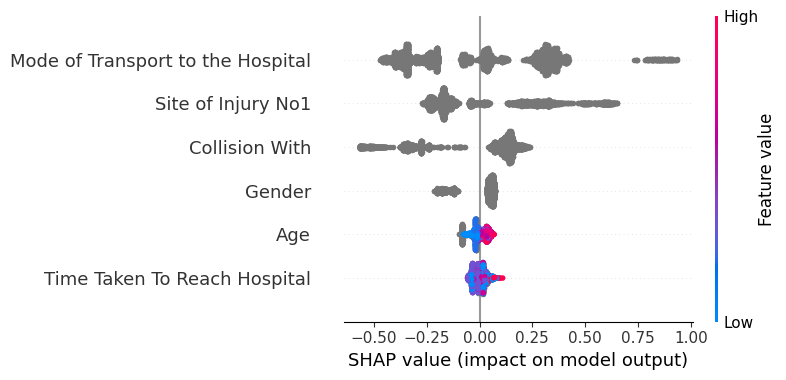

Mode of Transport to the Hospital    0.280602
Site of Injury No1                   0.219176
Collision With                       0.189219
Gender                               0.080960
Age                                  0.031499
Time Taken To Reach Hospital         0.024282
dtype: float64


In [ ]:
if FINAL_MODEL2 == 'CatBoost':
    explainer2 = shap.TreeExplainer(final_model2)
    shap_values2 = explainer2.shap_values(Pool(X2_train_enc, cat_features=cat_idx2))
    shap.summary_plot(shap_values2, X2_train_enc, show=False)
    plt.tight_layout()
    plt.savefig('artifacts/stage2_shap.png', dpi=150)
    plt.show()
    importance2 = pd.Series(np.abs(shap_values2).mean(axis=0), index=X2_train_enc.columns).sort_values(ascending=False)
else:
    pre = final_model2.named_steps['pre']
    clf = final_model2.named_steps['clf']
    coefs = pd.Series(np.abs(clf.coef_[0]), index=pre.get_feature_names_out())
    importance2 = coefs.sort_values(ascending=False)

print(importance2)

## 25. Final check on the held-out test data

Used exactly once, on the model and threshold chosen in Section 23.

                     precision    recall  f1-score   support

Acuity level 1 of 2       0.86      0.53      0.66       941
Acuity level 2 of 2       0.33      0.73      0.45       294

           accuracy                           0.58      1235
          macro avg       0.60      0.63      0.56      1235
       weighted avg       0.74      0.58      0.61      1235



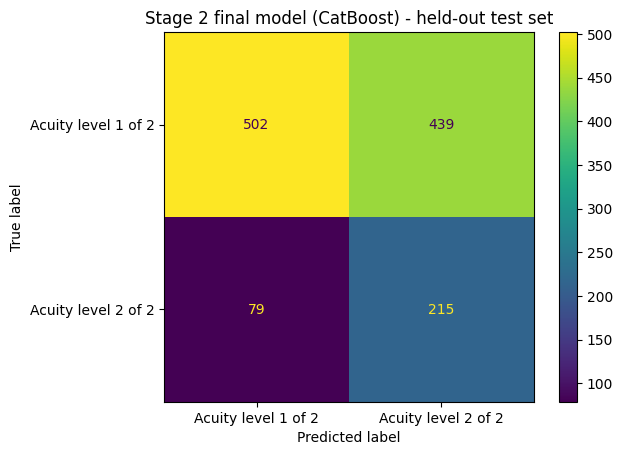


Test recall(higher-acuity): 0.731  precision: 0.329  recall(lower-acuity): 0.533


In [ ]:
proba_test2 = final_model2.predict_proba(X2_test_enc)
pos_idx2 = list(final_model2.classes_).index(POS_CLASS2)
y_pred_test2 = np.where(proba_test2[:, pos_idx2] >= CHOSEN_THRESHOLD2, POS_CLASS2, LOWER_CLASS2)

print(classification_report(y2_test, y_pred_test2))

cm2 = confusion_matrix(y2_test, y_pred_test2, labels=[LOWER_CLASS2, POS_CLASS2])
ConfusionMatrixDisplay(cm2, display_labels=[LOWER_CLASS2, POS_CLASS2]).plot()
plt.title(f'Stage 2 final model ({FINAL_MODEL2}) - held-out test set')
plt.savefig('artifacts/stage2_confusion_matrix.png', dpi=150)
plt.show()

test_recall2 = recall_score(y2_test, y_pred_test2, pos_label=POS_CLASS2)
test_precision2 = precision_score(y2_test, y_pred_test2, pos_label=POS_CLASS2)
test_recall_low2 = recall_score(y2_test, y_pred_test2, pos_label=LOWER_CLASS2)
print(f"\nTest recall(higher-acuity): {test_recall2:.3f}  precision: {test_precision2:.3f}  recall(lower-acuity): {test_recall_low2:.3f}")

## 26. A "how sure is this, really" layer

Same rule as every other model in this project: refuse below 40% feature completeness, flag
low-confidence below 60% model probability otherwise.

In [ ]:
COMPLETENESS_FLOOR2 = 0.40
LOW_CONF_PROB2 = 0.60

def predict_with_confidence2(record: dict, model=final_model2):
    non_missing = sum(1 for f in FEATURES2 if record.get(f) not in (None, np.nan) and
                       not (isinstance(record.get(f), float) and np.isnan(record.get(f))))
    completeness = non_missing / len(FEATURES2)
    if completeness < COMPLETENESS_FLOOR2:
        return {'prediction': None, 'completeness': completeness, 'status': 'REFUSED - under 40% complete'}

    row = pd.DataFrame([record])[FEATURES2]
    for col, order in [('Age', AGE_ORDER), ('Time Taken To Reach Hospital', TIME_ORDER)]:
        if col in row.columns:
            mapping = {v: i for i, v in enumerate(order)}
            row[col] = row[col].map(mapping)
    for c in CAT_FEATURES2:
        row[c] = row[c].astype(object).where(row[c].notna(), 'missing').astype(str)

    proba = model.predict_proba(row)[0]
    pred_idx = int(np.argmax(proba))
    pred_label = list(model.classes_)[pred_idx]
    pred_prob = float(proba[pred_idx])
    status = 'OK' if pred_prob >= LOW_CONF_PROB2 else 'LOW CONFIDENCE'
    return {'prediction': pred_label, 'probability': round(pred_prob, 3),
            'completeness': round(completeness, 3), 'status': status}

print(predict_with_confidence2(X2_test.iloc[0].to_dict()))
print(predict_with_confidence2({f: None for f in FEATURES2}))

{'prediction': 'Acuity level 2 of 2', 'probability': 0.618, 'completeness': 1.0, 'status': 'OK'}
{'prediction': None, 'completeness': 0.0, 'status': 'REFUSED - under 40% complete'}


## 27. Double-check: does dropping any feature actually help?

Every remaining feature passed Section 18 on its own - checked directly whether any is still
unhelpful once combined with the others.

In [ ]:
def cv_at_threshold2(cols, threshold, params):
    cat_cols_here = [c for c in cols if c in CAT_FEATURES2]
    cat_idx_here = [cols.index(c) for c in cat_cols_here]
    rec_pos, prec_pos, rec_low = [], [], []
    for tr_idx, val_idx in skf2.split(X2_train_enc[cols], y2_train):
        Xt, Xv = X2_train_enc[cols].iloc[tr_idx], X2_train_enc[cols].iloc[val_idx]
        yt, yv = y2_train.iloc[tr_idx], y2_train.iloc[val_idx]
        m = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, auto_class_weights='Balanced', **params)
        m.fit(Xt, yt, cat_features=cat_idx_here, verbose=0)
        proba = m.predict_proba(Xv)
        pos_idx = list(m.classes_).index(POS_CLASS2)
        pred = np.where(proba[:, pos_idx] >= threshold, POS_CLASS2, LOWER_CLASS2)
        rec_pos.append(recall_score(yv, pred, pos_label=POS_CLASS2))
        prec_pos.append(precision_score(yv, pred, pos_label=POS_CLASS2))
        rec_low.append(recall_score(yv, pred, pos_label=LOWER_CLASS2))
    return np.mean(rec_pos), np.mean(prec_pos), np.mean(rec_low)

baseline_ab2 = cv_at_threshold2(FEATURES2, CHOSEN_THRESHOLD2, best_params2)
ablation_rows2 = [{'dropped': '(none)', 'recall_pos': baseline_ab2[0], 'precision_pos': baseline_ab2[1], 'recall_low': baseline_ab2[2]}]
for f in FEATURES2:
    remaining = [c for c in FEATURES2 if c != f]
    r = cv_at_threshold2(remaining, CHOSEN_THRESHOLD2, best_params2)
    ablation_rows2.append({'dropped': f, 'recall_pos': r[0], 'precision_pos': r[1], 'recall_low': r[2]})

pd.DataFrame(ablation_rows2).sort_values('recall_pos', ascending=False)

,dropped,recall_pos,precision_pos,recall_low
3,Mode of Transport to the Hospital,0.774832,0.308578,0.456383
2,Gender,0.724713,0.327854,0.534309
4,Time Taken To Reach Hospital,0.717937,0.330756,0.544681
1,Age,0.716232,0.332847,0.549468
0,(none),0.715377,0.333491,0.551330
6,Site of Injury No1,0.706884,0.329467,0.550266
5,Collision With,0.684757,0.341706,0.586968


## 28. Save and document

In [ ]:
if FINAL_MODEL2 == 'CatBoost':
    final_model2.save_model('artifacts/stage2_severity_prediction_catboost.cbm')
else:
    import joblib
    joblib.dump(final_model2, 'artifacts/stage2_severity_prediction.joblib')

summary2 = {
    'stage': 2,
    'final_model': FINAL_MODEL2,
    'positive_class': POS_CLASS2,
    'arrival_candidate_features': ARRIVAL_CANDIDATE_FEATURES,
    'features_dropped': features2_to_drop,
    'final_features': FEATURES2,
    'chosen_threshold': CHOSEN_THRESHOLD2,
    'lower_class_recall_floor': LOWER_RECALL_FLOOR2,
    'held_out_test': {'recall_pos': float(test_recall2), 'precision_pos': float(test_precision2), 'recall_low': float(test_recall_low2)},
    'excluded_uncertain_rows': int((pd.concat([train_df, val_df])['severity_group_final'] == 'Uncertain').sum()),
    'notes': [
        "Trained only on patients Stage 1 confidently grouped - Uncertain cases excluded from training.",
        "Target is Stage 1's PCA+GMM-derived group, not a hand-engineered composite label.",
        "Same feature validation, joint model+threshold selection with guardrail, and confidence "
        "layer used throughout every other model in this project."
    ]
}
with open('artifacts/stage2_summary.json', 'w') as f:
    json.dump(summary2, f, indent=2)
print(json.dumps(summary2, indent=2))

{
  "stage": 2,
  "final_model": "CatBoost",
  "positive_class": "Acuity level 2 of 2",
  "arrival_candidate_features": [
    "Age",
    "Gender",
    "Mode of Transport to the Hospital",
    "Time Taken To Reach Hospital",
    "Vehicle Type",
    "Helmet Worn",
    "Collision With",
    "Site of Injury No1"
  ],
  "features_dropped": [
    "Vehicle Type",
    "Helmet Worn"
  ],
  "final_features": [
    "Age",
    "Gender",
    "Mode of Transport to the Hospital",
    "Time Taken To Reach Hospital",
    "Collision With",
    "Site of Injury No1"
  ],
  "chosen_threshold": 0.45000000000000007,
  "lower_class_recall_floor": 0.5,
  "held_out_test": {
    "recall_pos": 0.7312925170068028,
    "precision_pos": 0.3287461773700306,
    "recall_low": 0.5334750265674814
  },
  "excluded_uncertain_rows": 5,
  "notes": [
    "Trained only on patients Stage 1 confidently grouped - Uncertain cases excluded from training.",
    "Target is Stage 1's PCA+GMM-derived group, not a hand-engineered compo